In [1]:
import sys
sys.path.insert(0, 'C:/Users/au646858/OneDrive - Aarhus Universitet/Documents/_repositories/sea-anemone/app')
from temframe import TEMframe

torch detected, enabling torch tensor support in nosj


C:\Users/au646858/OneDrive - Aarhus Universitet/Documents/_repositories/sea-anemone/app\temframe.py:19: UserWarning: The default iteration cap for TEMframe inversion has been reduced to 10 to speed up testing. Change it back to 50 for production runs.
  warnings.warn("The default iteration cap for TEMframe inversion has been reduced to 10 to speed up testing. Change it back to 50 for production runs.", UserWarning)


In [2]:
df = TEMframe.from_usfzip("C:/Users/au646858/Downloads/Eliye_Spring_1_usf.zip")

In [ ]:
from anemone.inversion import LogResistivity

df.invert()

In [3]:
df.overview()

,date,daytime,distance,elevation,latitude,longitude,utm_x,utm_y
site_id,,,,,,,,
0,20251114.0,7.11139,0.000000,384.0,3.252806,36.020579,168846.315926,360025.538637
1,20251114.0,7.19750,73.463246,388.0,3.252174,36.020378,168823.704101,359955.641900
2,20251114.0,7.26167,119.876414,376.0,3.251761,36.020453,168831.912844,359909.960408
3,20251114.0,7.31972,139.196483,384.0,3.251620,36.020351,168820.508338,359894.365463
4,20251114.0,7.42194,216.318188,395.0,3.251265,36.019754,168754.044246,359855.246647
...,...,...,...,...,...,...,...,...
56,20251114.0,11.85667,2465.920572,419.0,3.242479,36.004571,167062.067619,358887.769510
57,20251114.0,11.93528,2509.517109,419.0,3.242141,36.004370,167039.573373,358850.424270
58,20251114.0,12.01611,2555.660416,419.0,3.241808,36.004120,167011.674064,358813.670584


In [4]:
df.forward_operators[1].save('forward_operator_0.json')

In [5]:
from anemone.forwards import Forward

fwr1 = Forward.load('forward_operator_0.json')

In [6]:
import torch
rho = torch.tensor([2.0, 3.0, 4.0])*10
thick = torch.tensor([1.0, 2.0])*10
dbdt = fwr1(rho, thick)

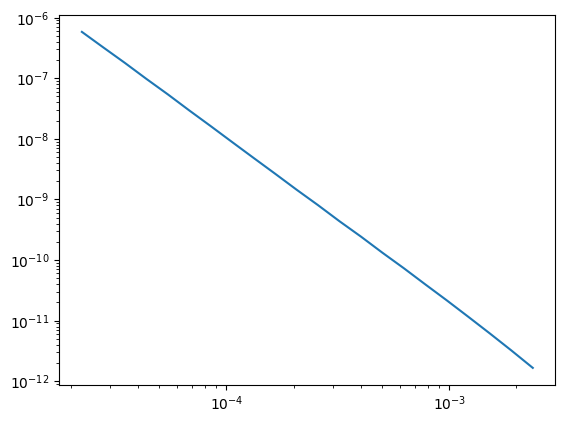

In [7]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.loglog(fwr1.times, dbdt)

In [8]:
from panels import *

dbdt_panel = dbdtSounding(dataframe=df)
dbdt_panel.render()